# Regression tests

Regression tests make sure a change in one place does not quietly break something that already
worked. DocuLens uses **generated passports with known answers**, scored automatically.

[`scripts/synthetic_passports.py`](../scripts/synthetic_passports.py) creates passport pages that follow
the shared ICAO 9303 layout without copying any real country's design:

- invented people, numbers and authorities, with a SPECIMEN watermark;
- 10 issuing countries, including a fictional one;
- captions in one, two or three languages (English, French, Spanish, German, Dutch), sometimes numbered;
- three layouts: caption above the value, beside it ("Surname: X"), and two columns;
- side-by-side columns on the top row, as on many European passports;
- four date styles (`23 FEB 1970`, `10 MAA/MAR 1965`, `23.02.1970`, `23/02/1970`);
- a correct MRZ with valid check digits.

Generated pages are cleaner than real photos (no holograms, glare or worn paper), so treat these
numbers as an upper bound. The full run takes about 8 minutes; lower `STRESS_LIMIT` to go faster.

In [1]:
from report_helpers import *  # noqa: F403  (paths and small display helpers)

STRESS_LIMIT = 8  # generated passports per condition

## One of the generated passports

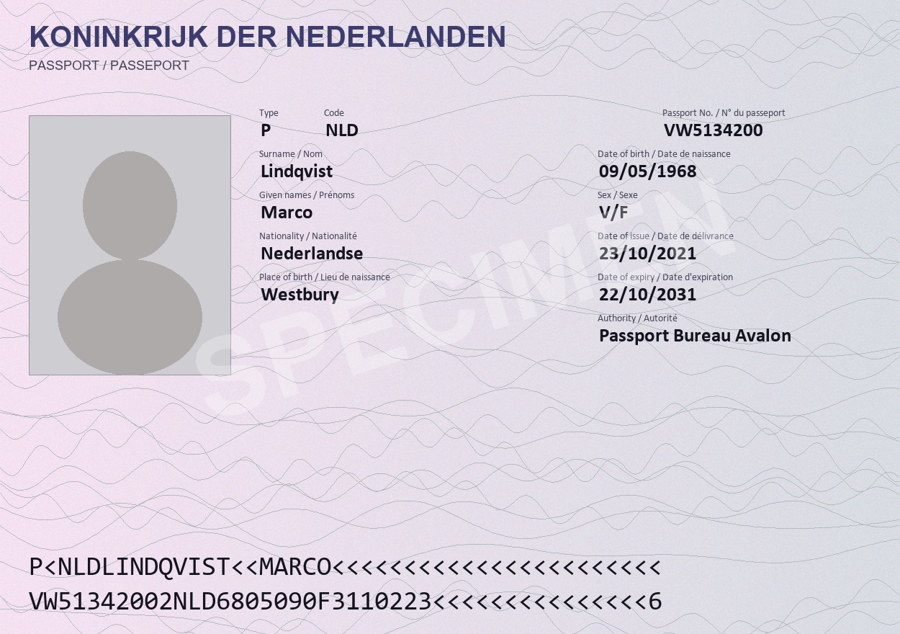

In [2]:
from PIL import Image

if not (SYNTHETIC / "answers.json").exists():
    run([PY, "scripts/synthetic_passports.py", "generate", "--count", "24"], PROJECT)
sample = Image.open(SYNTHETIC / "specimen-003.png")
sample.thumbnail((900, 900))
sample

## Clean pages

In [3]:
clean = synthetic_evaluation("clean", 24)
correct, total = map(sum, zip(*accuracy(clean, lambda row, field: "all").values()))
print(f"{correct}/{total} fields correct over {len(clean)} passports, "
      f"{sum(r['seconds'] for r in clean) / len(clean):.1f} s per scan")
display(Markdown(bar(correct / total)))

288/288 fields correct over 24 passports, 4.1 s per scan


`██████████████████████████████ 100.0%`

## Eight photo conditions

| Condition | What is done to the image |
|---|---|
| clean | Unchanged |
| rot90, rot180 | Turned sideways or upside down |
| tilt | Rotated 5–9° |
| blur | Gaussian blur |
| lowres | Half size |
| jpeg | Heavy JPEG compression (quality 45) |
| desk | Placed on a dark background, slightly tilted, as in a photo |

In [4]:
stress = synthetic_evaluation("clean,rot90,rot180,tilt,blur,lowres,jpeg,desk", STRESS_LIMIT)
by_condition = accuracy(stress, lambda row, field: row["variant"])
by_field = accuracy(stress, lambda row, field: field.replace("_", " "))
correct, total = map(sum, zip(*by_condition.values()))
print(f"{correct}/{total} fields correct over {len(stress)} scans, "
      f"{sum(r['seconds'] for r in stress) / len(stress):.1f} s per scan")
table(["Condition", "Correct", "Accuracy"], [[name, f"{a}/{b}", bar(a / b)] for name, (a, b) in by_condition.items()])
table(["Field", "Correct"], [[name, f"{a}/{b}"] for name, (a, b) in sorted(by_field.items(), key=lambda x: x[1][0] / x[1][1])])

766/768 fields correct over 64 scans, 4.6 s per scan


| Condition | Correct | Accuracy |
|---|---|---|
| clean | 96/96 | `██████████████████████████████ 100.0%` |
| rot90 | 96/96 | `██████████████████████████████ 100.0%` |
| rot180 | 96/96 | `██████████████████████████████ 100.0%` |
| tilt | 96/96 | `██████████████████████████████ 100.0%` |
| blur | 96/96 | `██████████████████████████████ 100.0%` |
| lowres | 96/96 | `██████████████████████████████ 100.0%` |
| jpeg | 94/96 | `█████████████████████████████░ 97.9%` |
| desk | 96/96 | `██████████████████████████████ 100.0%` |

| Field | Correct |
|---|---|
| nationality code | 62/64 |
| surname | 64/64 |
| given names | 64/64 |
| document number | 64/64 |
| date of birth | 64/64 |
| sex | 64/64 |
| place of birth | 64/64 |
| date of issue | 64/64 |
| date of expiry | 64/64 |
| issuing authority | 64/64 |
| issuing country code | 64/64 |
| document code | 64/64 |

## Every field that was wrong

In [5]:
mistakes = [[row["id"], row["variant"], field.replace("_", " "), expected, got]
            for row in stress for field, (expected, got) in row["wrong"].items()]
table(["Passport", "Condition", "Field", "Expected", "Read"], mistakes) if mistakes else print("None")

| Passport | Condition | Field | Expected | Read |
|---|---|---|---|---|
| specimen-004 | jpeg | nationality code | ESP | Española |
| specimen-005 | jpeg | nationality code | UTO | Utopian |

## How these results improved

| Stage | Clean pages |
|---|---:|
| Before the fixes of 12 November 2026 | 87 % |
| After the fixes | 100 % |

The fixes were general rules, not special cases for one country: reading the whole image when
an automatic crop cuts through text; treating digits as letters where the passport standard allows
only letters (for example `0` → `O` in names); and taking a nationality's code from a checked MRZ
when the printed word is not in the local country list.